In [1]:
import sys
from importlib.metadata import version, PackageNotFoundError

print("Python executable:", sys.executable)
print("Python version:", sys.version.split()[0])

packages = [
    "torch",
    "torchvision",
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "Pillow",
    "matplotlib",
    "tqdm",
    "ipykernel",
]

for package in packages:
    try:
        print(f"{package}=={version(package)}")
    except PackageNotFoundError:
        print(f"{package}: not installed")

Python executable: /home/sc8qs/.conda/envs/ds6050/bin/python
Python version: 3.12.14
torch==2.7.0+cu126
torchvision==0.22.0+cu126
numpy==2.2.6
pandas==2.2.3
scipy==1.15.2
scikit-learn==1.6.1
Pillow==11.1.0
matplotlib==3.10.1
tqdm==4.67.1
ipykernel==7.4.0


# Run the Three Actual VGG16 Baseline Experiments

**Save this notebook in your HPC working directory, restart the kernel, and choose Run All.**

With `RUN_EXPERIMENTS=True` (only when intentionally enabled), this notebook trains **nine fresh runs**: age-only, sex-only, and joint age-and-sex, each with seeds 101, 202, and 303 and a 10-epoch budget. It then evaluates each selected checkpoint on the held-out TEST set and writes the per-seed results, mean/sample SD, paired comparisons, and prediction files. It never imports previous run locations or skips an experiment because an older checkpoint exists.

For normal team setup, use your already-extracted images and the exact shared cohort files from `data/cohort/`. The archives and `imdb.mat` are only needed for explicitly enabled extraction or first-time cohort preparation. `PREPARE_ARCHIVES`, `RUN_EXTRACTION_RECOVERY`, and `BUILD_COHORT_IF_MISSING` default to False to prevent unnecessary scans or a different dataset split.

Preparation requires SciPy and scikit-learn in addition to PyTorch, torchvision, pandas, NumPy, Pillow, and matplotlib. Extraction uses Python's `tarfile` data filter (available in supported recent Python versions). Existing extraction completion records avoid unpacking the archives again. After an interrupted extraction, rerun the preparation cell.

Each execution of the settings cell creates a new timestamped session folder under `studies/vgg16_common_cohort_v1/baseline_reruns/`. Your earlier run folders remain untouched. Run the training cell once per session. Set `RUN_EXPERIMENTS=False` only if you want to inspect definitions without starting experiments.

**Experimental rules:** same finalized cohort and person-disjoint splits, ImageNet VGG16, frozen blocks 1–4, AdamW, no random augmentation, and matched seed panel. Gradients use training data; the lowest validation objective chooses one checkpoint per run; TEST data reports final performance. Do not tune settings or select seeds using TEST results. This follows [Shakeri's experimental workflow](https://shakeri-lab.github.io/dl-book/chapters/interludes/learning-by-experiment.html).

**TEST report:** age-only gives standardized-age loss and MAE in years; sex-only gives cross-entropy and classification error/accuracy percentages; joint gives `wage × standardized-age MAE + wgender × cross-entropy` plus each task's error. Both weights are fixed at 1. Different raw loss scales do not provide a universal ranking across the three models. Sample SD across three seeds describes training variability on the fixed dataset.


## Shared-setup repair

The overwritten cohort cell has been restored. For teammates: start the kernel in the repo root, set `DATA_DIR` in the settings cell (or export `MLIII_DATA_DIR`) to your own scratch dataset directory containing `imdb_crop/`, and leave training/testing/recovery/extraction flags **False** during setup verification. The exact split CSVs and cohort protocol must be available under the repo's `data/cohort/` directory; a complete matching local cohort is also accepted. Loading these saved splits needs neither the tar files nor `imdb.mat`.

Restart the kernel and run shared setup through `FaceDataset`/loader definitions. Confirm that the cohort cell prints split counts and age statistics, and the protocol and loader definitions execute without a NameError. Do not rerun baseline training merely to verify this repair. Original saved experimental outputs below are historical baseline evidence, not outputs from executing this repaired file.



## Data Loading and Setup:

First, we load the packages we need to read the images and metadata, build the PyTorch models, manage experiment files, and plot results. We also set up progress bars so we can see that the code is moving. Then we define our working paths and create a timestamped results folder so each new session keeps its own outputs instead of overwriting an earlier experiment.

We keep the main settings together so all three models follow the same recipe: age-only, sex-only, and joint learning, each trained with seeds 101, 202, and 303 for nine total runs. We use 10 epochs, batches of 16 images, and four data-loading workers to help keep the GPU supplied with images. Both joint-loss weights start at 1, which gives us a fixed starting rule without assuming the tasks have equal gradient influence. Finally, we enable training and test evaluation, select CUDA if it’s available, and print the device and results location so we can confirm where everything is running.

In [ ]:
# File paths, timestamps, date calculations, and experiment-status tracking.
from pathlib import Path
from datetime import datetime, timezone, timedelta
from contextlib import contextmanager

# Helpers for memory cleanup, checksums, saved records, reproducibility,
# file copying, timing, error logs, and unpacking the dataset.
import os, gc, hashlib, json, platform, random, shutil, time, traceback, tarfile

# Read MATLAB metadata and split by celebrity ID to reduce data leakage.
from scipy.io import loadmat
from sklearn.model_selection import GroupShuffleSplit

# Work with numerical arrays, metadata tables, plots, and image files.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Build/train the models and load images in batches.
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Use ImageNet-pretrained VGG16 and record the torchvision version later.
from torchvision.models import vgg16, VGG16_Weights
import torchvision

# Show batch progress when tqdm is installed.
# If it isn't available, keep running without a progress bar.
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(iterable, **kwargs): return iterable


# Start the kernel in the repository root so data/cohort and this notebook resolve.
# Each teammate can point DATA_DIR at their OWN extracted dataset directory.
PROJECT_DIR = Path.cwd().resolve()
DATA_DIR = Path(os.environ.get("MLIII_DATA_DIR", str(PROJECT_DIR))).expanduser().resolve()
# Example: DATA_DIR = Path("/sfs/weka/scratch/YOUR_ID").resolve()
WORK_DIR = DATA_DIR
IMAGE_ROOT = DATA_DIR / 'imdb_crop'
METADATA_PATH = DATA_DIR / 'imdb' / 'imdb.mat'

# Shared split files live in the repo, independently of where images are stored.
COHORT_SOURCE_DIR = PROJECT_DIR / 'data' / 'cohort'
COHORT_DIR = PROJECT_DIR / 'studies' / 'vgg16_common_cohort_v1'

# Default team workflow: reuse extracted images and the exact approved splits.
RUN_EXTRACTION_RECOVERY = False
PREPARE_ARCHIVES = False
BUILD_COHORT_IF_MISSING = False  # Only for deliberate first-time dataset preparation.

# Give each session a timestamped folder so we preserve earlier results.
# IMPORTANT: rerunning this cell creates a new folder even with training off.
SESSION_NAME = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
RESULTS_DIR = COHORT_DIR / 'baseline_reruns' / SESSION_NAME

# Create missing parent folders, but stop if this exact session folder exists.
RESULTS_DIR.mkdir(parents=True, exist_ok=False)

# Save a copy of this notebook with each run to record the code we used.
# Save the notebook before launching experiments.
NOTEBOOK_PATH = PROJECT_DIR / 'MLIII_Group3_Project_Code.ipynb'

# Compare three model types across the same three training seeds:
# three models × three seeds = nine runs.
# The seeds vary training randomness while the data splits stay fixed.
TASKS, SEEDS = ('age_only', 'sex_only', 'joint'), (101, 202, 303)

# Keep the training budget and batch size consistent across models.
# Four workers prepare batches while the GPU processes them.
EPOCHS, BATCH_SIZE, NUM_WORKERS = 10, 16, 4

# Fixed weights for the joint objective:
# total loss = WAGE × standardized-age MAE + WGENDER × sex BCE.
# Equal weights don't guarantee equal influence on the gradients.
WAGE, WGENDER = 1.0, 1.0

# Baselines are finished, so leave execution off to avoid accidental retraining.
# True enables the later training cell to launch all nine fresh runs.
RUN_EXPERIMENTS = False  # Run All trains nine fresh runs, then evaluates TEST results.

# Control test evaluation independently. Both execution flags stay off for setup checks.
EVALUATE_TEST = False

# Use the allocated NVIDIA GPU when CUDA is available; otherwise use the CPU.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Confirm our working directory, compute device, and new output location.
# This cell sets things up; training starts in a later cell.
print('Repository:', PROJECT_DIR)
print('Dataset directory:', DATA_DIR, '| Device:', device)
if device.type == 'cuda': print('GPU:', torch.cuda.get_device_name(0))
print('New experiment session:', RESULTS_DIR)


### Optional extraction recovery — disabled by default

This cell is only for an interrupted extraction. Leave `RUN_EXTRACTION_RECOVERY=False` for normal team setup. If recovery is needed, first set `DATA_DIR` in the settings cell to your own dataset location, then enable recovery explicitly. It does not use Savanna's account path.


In [ ]:
if RUN_EXTRACTION_RECOVERY:
    # Helpers for file paths, archive extraction, checksums, and saved records.
    from pathlib import Path, PurePosixPath
    import tarfile
    import hashlib
    import json

    # Use the dataset location selected in the shared settings cell.
    WORK_DIR = DATA_DIR
    archive_path = WORK_DIR / "imdb_crop.tar"
    record_path = WORK_DIR / "dataset_extraction.json"

    # Stop early if the archive isn't where we expect it.
    assert archive_path.is_file(), archive_path

    # Track what we actually extract versus what we can reuse.
    extracted = 0
    skipped = 0
    checked = 0

    # This recovery cell scans the archive even if extraction already finished.
    # We only need it after an interrupted extraction. (I fudged it first time, lmao)
    print(
        "Resuming image extraction. Existing complete-size files will be skipped.",
        flush=True,
    )

    # Open the archive and check its entries one at a time.
    with tarfile.open(archive_path, mode="r:*") as archive:
        for member in archive:
            # Directory entries don't need file-size checks.
            # Extraction creates the parent directories when needed.
            if member.isdir():
                continue

            # Read the archive's path using its forward-slash format.
            relative = PurePosixPath(member.name)

            # Only accept regular files inside the expected imdb_crop folder.
            # Reject absolute paths, parent-directory traversal, and links.
            if (
                not member.isfile()
                or relative.is_absolute()
                or ".." in relative.parts
                or relative.parts[0] != "imdb_crop"
            ):
                raise RuntimeError(
                    f"Unexpected archive entry: {member.name}"
                )

            destination = WORK_DIR / member.name

            # Compare the existing file size with the archive's recorded size.
            # A missing file or a different size means we need to extract it.
            try:
                matching_size = destination.stat().st_size == member.size
            except FileNotFoundError:
                matching_size = False

            if matching_size:
                # Avoid rewriting files that appear to have finished extracting.
                # Matching size alone doesn't guarantee valid image contents;
                # the later data-preparation block checks image readability.
                skipped += 1
            else:
                # Extract missing or incomplete-size files.
                # The data filter adds safeguards during extraction.
                archive.extract(
                    member,
                    path=WORK_DIR,
                    filter="data",
                )
                extracted += 1

            checked += 1

            # Print progress so a long scan doesn't look like a frozen cell.
            if checked % 10_000 == 0:
                print(
                    f"Checked {checked:,} | "
                    f"Skipped {skipped:,} | "
                    f"Extracted/repaired {extracted:,}",
                    flush=True,
                )

    print(
        "File extraction finished. Calculating archive checksum...",
        flush=True,
    )

    # Identify the archive with a SHA-256 checksum.
    # Read it in 8 MiB chunks instead of loading the whole archive into memory.
    # This hashes the archive itself, not each extracted image.
    digest = hashlib.sha256()
    with open(archive_path, "rb") as file:
        for chunk in iter(lambda: file.read(8 * 1024 * 1024), b""):
            digest.update(chunk)

    # Keep any existing records, including metadata-archive extraction records.
    stat = archive_path.stat()
    records = (
        json.loads(record_path.read_text())
        if record_path.exists()
        else {}
    )

    # Record completion only after the extraction scan and checksum finish.
    # The regular extraction cell uses the size and modification time
    # to recognize the archive, and retains its checksum for identification.
    records["imdb_crop.tar"] = {
        "signature": {
            "size": stat.st_size,
            "mtime_ns": stat.st_mtime_ns,
        },
        "sha256": digest.hexdigest(),
    }

    # Save the completion record so the regular extraction cell can skip
    # unpacking this archive again when its checks match.
    record_path.write_text(json.dumps(records, indent=2))

    print(
        f"Finished: skipped {skipped:,}; "
        f"extracted/repaired {extracted:,}."
    )
    print(
        "Completion recorded. "
        "The notebook will skip image extraction next time."
    )
else:
    print('Image-extraction recovery disabled; existing images are reused.')


Now we define two helpers for keeping our files and experiment records consistent. sha256() calculates a file checksum in small chunks so we don’t load a huge archive into memory. frozen_json() saves a record if it doesn’t exist, but stops if an existing record contains different information. This helps prevent us from quietly changing the settings or data definitions attached to an experiment.

Then we handle extraction for both the image and metadata archives. We check the saved completion record against each archive’s size and modification time, confirm the expected destination exists, and skip extraction when those checks match. Otherwise, we unpack the archive using the data safety filter, verify the expected folder or metadata file, and record completion with the archive checksum. This avoids repeating successful extraction while still giving us a record of which archives we used. Finally, we set METADATA_PATH so the next block knows where to find imdb.mat.

In [ ]:
# Calculate a file checksum so we can identify the exact file we used.
def sha256(path):
    digest = hashlib.sha256()

    # Read in 8 MiB chunks so a large archive doesn't fill our memory.
    with open(path, 'rb') as file:
        for chunk in iter(lambda: file.read(8 * 1024 * 1024), b''):
            digest.update(chunk)

    return digest.hexdigest()


# Save an experiment record without silently replacing different settings.
def frozen_json(path, payload):
    text = json.dumps(payload, indent=2, sort_keys=True)

    # Stop if this record already exists with different contents.
    # A revised study should get its own version rather than overwrite history.
    if path.exists() and json.loads(path.read_text()) != payload:
        raise RuntimeError(
            f'Frozen record differs: {path}. '
            'Preserve it and version any revised study.'
        )

    # An identical existing record can stay as it is.
    if not path.exists():
        path.write_text(text)


archive_records = {}

if PREPARE_ARCHIVES:
    # Load completion records from earlier extraction attempts.
    # This also recognizes the record created by our recovery cell.
    extraction_record_path = WORK_DIR / 'dataset_extraction.json'
    extraction_records = (
        json.loads(extraction_record_path.read_text())
        if extraction_record_path.exists()
        else {}
    )

    # Keep the source records available for the later data-preparation block.
    archive_records = {}

    # Handle the face images and MATLAB metadata separately.
    for filename, destination in [
        ('imdb_crop.tar', IMAGE_ROOT),
        ('imdb_meta.tar', WORK_DIR / 'imdb'),
    ]:
        archive_path = WORK_DIR / filename

        # Stop before doing more work if an archive is missing.
        if not archive_path.is_file():
            raise FileNotFoundError(
                f'Place {filename} beside the notebook: {archive_path}'
            )

        # Use archive size and modification time as a quick cache check.
        # This avoids recalculating the archive checksum on every run.
        stat = archive_path.stat()
        signature = {
            'size': stat.st_size,
            'mtime_ns': stat.st_mtime_ns,
        }
        prior = extraction_records.get(filename, {})

        # Require a matching completion record and the expected directory.
        # This does not inspect every previously extracted image.
        completed = (
            prior.get('signature') == signature
            and destination.is_dir()
        )

        # For metadata, also confirm that imdb.mat is actually present.
        if filename == 'imdb_meta.tar':
            completed = (
                completed
                and (destination / 'imdb.mat').is_file()
            )

        if completed:
            print('Already extracted:', filename)
            archive_records[filename] = prior
            continue

        # Require Python's data extraction filter for safer archive handling.
        if not hasattr(tarfile, 'data_filter'):
            raise RuntimeError(
                'Use a Python version with tarfile.data_filter '
                'before extracting these archives.'
            )

        # Without a recognized completion record, this extracts the whole archive.
        # After an interrupted image extraction, use our recovery cell first
        # to avoid rewriting all the files that already finished.
        print('Extracting:', filename, flush=True)

        with tarfile.open(archive_path, 'r:*') as archive:
            archive.extractall(WORK_DIR, filter='data')

        # Confirm the expected output exists before recording completion.
        if not destination.is_dir():
            raise RuntimeError(
                f'Expected archive directory missing: {destination}'
            )

        if (
            filename == 'imdb_meta.tar'
            and not (destination / 'imdb.mat').is_file()
        ):
            raise RuntimeError(
                'Expected imdb/imdb.mat was not extracted.'
            )

        # Hash the archive after extraction and retain its identifying information.
        # This stage can take time even though unpacking has already finished.
        archive_records[filename] = {
            'signature': signature,
            'sha256': sha256(archive_path),
        }

        # Save after each archive so completing one doesn't depend on the other.
        extraction_records[filename] = archive_records[filename]
        extraction_record_path.write_text(
            json.dumps(extraction_records, indent=2)
        )

        print('Finished:', filename, flush=True)


else:
    print('Archive extraction disabled. Using images already present at:', IMAGE_ROOT)

METADATA_PATH = DATA_DIR / 'imdb' / 'imdb.mat'


### Load the common cohort used for the baselines

Now we load the exact shared training, validation, and test image lists. With a fresh clone, this cell copies the files from `data/cohort/` into the local study folder and verifies their checksums. It defines `frames`, `AGE_MEAN`, `AGE_STD`, `cohort_protocol`, and `manifest_hashes` for the later cells. Image paths are rebuilt from each teammate's `DATA_DIR`; no one needs access to Savanna's personal scratch directory.

If approved files are missing or inconsistent, we stop instead of silently generating a different cohort. The original metadata preparation is retained only behind the explicit `BUILD_COHORT_IF_MISSING` setting for deliberate first-time preparation. Keep that flag **False** for augmentation comparisons. Existing baseline models and outcomes do not need retraining.


In [ ]:
# Team default: copy the exact approved split records from the repository,
# then let the original preparation/loading code verify and load them.
# This preserves split assignments and label eligibility from the baseline study.
required_names = ('train.csv', 'validation.csv', 'test.csv', 'protocol.json')
required_local = [COHORT_DIR / name for name in required_names]
required_shared = [COHORT_SOURCE_DIR / name for name in required_names]
local_present = [path.is_file() for path in required_local]
shared_complete = all(path.is_file() for path in required_shared)

if not IMAGE_ROOT.is_dir():
    raise FileNotFoundError(
        f'Extracted images not found: {IMAGE_ROOT}. Set DATA_DIR to your own dataset directory '
        'in the settings cell. For a new extraction, enable PREPARE_ARCHIVES explicitly.'
    )

if any(local_present) and not all(local_present):
    raise RuntimeError(
        f'Incomplete local split records in {COHORT_DIR}. Restore all four files from '
        'data/cohort together; do not regenerate different splits for an augmentation run.'
    )

if all(local_present):
    # If both copies exist, they must identify the same baseline cohort.
    if shared_complete:
        for source, destination in zip(required_shared, required_local):
            if sha256(source) != sha256(destination):
                raise RuntimeError(
                    f'Local cohort differs from the shared repo: {destination.name}. '
                    'Resolve the mismatch before running experiments.'
                )
elif shared_complete:
    # Validate source hashes before copying any split files.
    saved_protocol = json.loads((COHORT_SOURCE_DIR / 'protocol.json').read_text())
    for split in ('train', 'validation', 'test'):
        source = COHORT_SOURCE_DIR / f'{split}.csv'
        if sha256(source) != saved_protocol['manifest_sha256'][split]:
            raise RuntimeError(f'Shared split checksum mismatch: {source}')
    COHORT_DIR.mkdir(parents=True, exist_ok=True)
    for name in required_names:
        shutil.copy2(COHORT_SOURCE_DIR / name, COHORT_DIR / name)
    source_hashes = COHORT_SOURCE_DIR / 'source_hashes.json'
    if source_hashes.is_file():
        shutil.copy2(source_hashes, COHORT_DIR / source_hashes.name)
    print('Restored exact shared split files from:', COHORT_SOURCE_DIR)
elif not BUILD_COHORT_IF_MISSING:
    raise FileNotFoundError(
        f'Approved splits are missing. Start the kernel in the repository root and restore '
        f'{COHORT_SOURCE_DIR}/{{train.csv,validation.csv,test.csv,protocol.json}} from GitHub. '
        'Do not create new splits for the augmentation experiments.'
    )
else:
    # Deliberate first-time preparation remains available, but is never the team default.
    if not METADATA_PATH.is_file():
        raise FileNotFoundError(f'Metadata not found: {METADATA_PATH}. Extract metadata first.')


# Reuse approved manifests, or create them from imdb.mat on the first run.
cohort_protocol_path = COHORT_DIR / 'protocol.json'
required = [COHORT_DIR / f'{s}.csv' for s in ('train', 'validation', 'test')] + [cohort_protocol_path]
present = [path.exists() for path in required]
if any(present) and not all(present):
    raise RuntimeError('The cohort has partial preparation files. Preserve these and use a new COHORT_DIR or restore the complete set.')

def age_at_midyear(dob, photo_year):
    try:
        if not np.isfinite(dob) or not np.isfinite(photo_year) or photo_year != int(photo_year): return np.nan
        born = (datetime.fromordinal(int(dob)) - timedelta(days=366)).date()
        photographed = datetime(int(photo_year), 7, 1).date()
        if born > photographed: return np.nan
        age = photographed.year - born.year - ((7, 1) < (born.month, born.day))
        return float(age) if 0 <= age <= 100 else np.nan
    except (TypeError, ValueError, OverflowError): return np.nan

source_path = COHORT_DIR / 'source_hashes.json'
if source_path.exists():
    original_sources = json.loads(source_path.read_text())
    for filename, record in archive_records.items():
        if filename in original_sources:
            assert original_sources[filename]['sha256'] == record['sha256'], 'Archives differ from the saved cohort sources.'

if not all(present):
    print('Preparing the common cohort from imdb.mat...', flush=True)
    metadata = loadmat(METADATA_PATH, simplify_cells=True)['imdb']
    flatten = lambda name: np.asarray(metadata[name]).reshape(-1)
    data = pd.DataFrame({'relative_path': flatten('full_path').astype(str),
        'sex': flatten('gender').astype(float), 'person_id': flatten('celeb_id'),
        'face_score': flatten('face_score').astype(float),
        'second_face_score': flatten('second_face_score').astype(float),
        'age': [age_at_midyear(d, y) for d, y in zip(flatten('dob'), flatten('photo_taken'))]})
    # Exclude conflicting repeated-path metadata rather than choosing an arbitrary label/person.
    conflicts = data.groupby('relative_path')[['sex', 'person_id', 'age']].nunique(dropna=False).gt(1).any(axis=1)
    data = data.loc[~data['relative_path'].isin(conflicts[conflicts].index)].copy()
    data = data.loc[data['sex'].isin([0, 1]) & np.isfinite(data['face_score'])
                    & data['second_face_score'].isna() & data['person_id'].notna()].reset_index(drop=True)
    # Split people before age filtering, matching the original workflow's order.
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    train_ids, remaining_ids = next(splitter.split(data, groups=data['person_id']))
    remaining = data.iloc[remaining_ids].reset_index(drop=True)
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=43)
    val_ids, test_ids = next(splitter.split(remaining, groups=remaining['person_id']))
    prepared = {'train': data.iloc[train_ids].copy(), 'validation': remaining.iloc[val_ids].copy(),
                'test': remaining.iloc[test_ids].copy()}
    for split, frame in prepared.items():
        prepared[split] = frame.loc[frame['age'].notna()].drop_duplicates('relative_path').reset_index(drop=True)
    candidates = pd.concat([f.assign(split=s) for s,f in prepared.items()], ignore_index=True)
    audit = []
    for i, row in enumerate(candidates.itertuples(index=False), 1):
        path = IMAGE_ROOT / row.relative_path
        record = {'split': row.split, 'relative_path': row.relative_path, 'image_sha256': '', 'error': ''}
        try:
            # These are metadata-derived paths, and must remain inside the image directory.
            if not path.resolve().is_relative_to(IMAGE_ROOT.resolve()): raise ValueError('Image path escapes IMAGE_ROOT')
            with Image.open(path) as image: image.convert('RGB').load()
            record['image_sha256'] = sha256(path)
        except (OSError, ValueError) as error: record['error'] = repr(error)
        audit.append(record)
        if i % 10000 == 0: print(f'Prepared {i:,}/{len(candidates):,} images', flush=True)
    audit = pd.DataFrame(audit)
    valid = audit.loc[audit['error'].eq('')]
    duplicate_splits = valid.groupby('image_sha256')['split'].nunique()
    leaked_hashes = set(duplicate_splits[duplicate_splits > 1].index)
    exclusions = audit.loc[audit['error'].ne('') | audit['image_sha256'].isin(leaked_hashes)]
    exclusions.to_csv(COHORT_DIR / 'image_exclusions.csv', index=False)
    for split, frame in prepared.items():
        hashes = valid.loc[valid['split'].eq(split), ['relative_path', 'image_sha256']]
        frame = frame.merge(hashes, on='relative_path', how='inner', validate='one_to_one')
        frame = frame.loc[~frame['image_sha256'].isin(leaked_hashes)].reset_index(drop=True)
        if frame.empty: raise ValueError(f'No eligible images in {split}.')
        frame['sex'] = frame['sex'].astype(int)
        prepared[split] = frame
    # All preparation checks finish before publishing the frozen manifests.
    for a,b in [('train','validation'), ('train','test'), ('validation','test')]:
        assert set(prepared[a]['person_id']).isdisjoint(prepared[b]['person_id'])
        assert set(prepared[a]['image_sha256']).isdisjoint(prepared[b]['image_sha256'])
    training_settings = {'epochs': EPOCHS, 'batch_size': BATCH_SIZE, 'optimizer': 'AdamW',
        'block5_lr': 1e-5, 'classifier_head_lr': 1e-4, 'weight_decay': 1e-4,
        'precision': 'float32', 'seeds': list(SEEDS), 'joint_weights': {'age': WAGE, 'sex': WGENDER}}
    selection_rules = {'age_only': 'minimum validation standardized MAE',
                      'sex_only': 'minimum validation BCE',
                      'joint': 'minimum validation standardized MAE plus BCE'}
    age_mean = float(prepared['train']['age'].mean())
    age_std = float(prepared['train']['age'].std(ddof=0))
    if not age_std > 0: raise ValueError('Training ages have zero variation.')
    for split, frame in prepared.items(): frame.to_csv(COHORT_DIR / f'{split}.csv', index=False)
    cohort_record = {'training': training_settings, 'selection': selection_rules,
        'data': {'age_range': [0,100], 'age_assumption': 'completed years at July 1 of photograph year',
                 'split_unit': 'celebrity ID', 'split_seeds': [42,43],
                 'same_eligible_images_for_all_tasks': True,
                 'age_mean_training_only': age_mean, 'age_std_training_only': age_std},
        'manifest_sha256': {s: sha256(COHORT_DIR / f'{s}.csv') for s in prepared},
        'metadata_sha256': sha256(METADATA_PATH)}
    cohort_protocol_path.write_text(json.dumps(cohort_record, indent=2))
    source_path.write_text(json.dumps(archive_records, indent=2))
    print('Common cohort created. Excluded unreadable/cross-split duplicate records:', len(exclusions))
else:
    print('Reusing finalized common-cohort split files.')

cohort_protocol = json.loads(cohort_protocol_path.read_text())
manifest_hashes = {s: sha256(COHORT_DIR / f'{s}.csv') for s in ('train', 'validation', 'test')}
assert manifest_hashes == cohort_protocol['manifest_sha256'], 'Cohort files changed.'
frames = {s: pd.read_csv(COHORT_DIR / f'{s}.csv') for s in manifest_hashes}
for split, frame in frames.items():
    assert len(frame) and frame['relative_path'].is_unique
    assert frame['sex'].isin([0, 1]).all() and frame['age'].between(0, 100).all()
    frame['path'] = frame['relative_path'].map(lambda p: str(IMAGE_ROOT / p))
for a,b in [('train','validation'), ('train','test'), ('validation','test')]:
    assert set(frames[a]['person_id']).isdisjoint(frames[b]['person_id'])
    assert set(frames[a]['image_sha256']).isdisjoint(frames[b]['image_sha256'])
AGE_MEAN = float(frames['train']['age'].mean())
AGE_STD = float(frames['train']['age'].std(ddof=0))
assert AGE_STD > 0
assert np.isclose(AGE_MEAN, cohort_protocol['data']['age_mean_training_only'])
assert np.isclose(AGE_STD, cohort_protocol['data']['age_std_training_only'])
print('Images per split:', {s:len(f) for s,f in frames.items()})
print('Training-only age mean/std:', AGE_MEAN, AGE_STD)


Now we record the rules for comparing our models and check that they match the settings saved during data preparation. This includes the epochs, batch size, optimizer, learning rates, seeds, and joint-loss weights. We also specify how we select checkpoints: lowest validation age loss for age-only, lowest validation cross-entropy for sex-only, and lowest combined validation loss for the joint model. If losses tie, we keep the earlier epoch. Setting these rules *before* looking at test results helps keep us from choosing whichever procedure makes a model look best afterward, aka no peeking

We save those settings alongside the data checksums, training-only age-scaling values, and test metrics so each session has a clear record of its procedure. *The comparison uses the same cohort, matched seeds, and a fixed training recipe, with no random augmentation*. Finally, we load the preprocessing associated with the ImageNet-pretrained VGG16 weights so our images have the expected size and normalization. PLEASE UNDERSTAND: This sets up the comparison, it doesn’t run training or test evaluation yet.

In [ ]:
# Keep the main training choices together so we can verify that each
# experiment follows the recipe saved during data preparation.
expected_training = {
    'epochs': EPOCHS,
    'batch_size': BATCH_SIZE,
    'optimizer': 'AdamW',

    # Make smaller updates to the pretrained convolutional block,
    # while allowing the classifier and task heads to adapt faster.
    'block5_lr': 1e-5,
    'classifier_head_lr': 1e-4,

    # Record regularization, numerical precision, and the full seed panel.
    'weight_decay': 1e-4,
    'precision': 'float32',
    'seeds': list(SEEDS),

    # Fix the joint-loss weights before evaluating test performance.
    # Equal weights don't guarantee equal gradient influence.
    'joint_weights': {
        'age': WAGE,
        'sex': WGENDER,
    },
}

# Stop if the current settings differ from the saved study settings.
# This helps us avoid silently changing the comparison between runs.
for key, value in expected_training.items():
    assert cohort_protocol['training'][key] == value, (
        f'Original protocol differs: {key}'
    )

# Specify how we select each model's checkpoint using VALIDATION data.
# The joint model gets one checkpoint selected by its combined objective,
# rather than separate checkpoints chosen for its two tasks.
selection = {
    'age_only': 'minimum validation standardized MAE',
    'sex_only': 'minimum validation BCE',
    'joint': 'minimum validation standardized MAE plus BCE',
}

# Confirm that these selection rules match the original protocol.
# The joint rule below describes our current weights of 1 for both tasks.
assert all(
    cohort_protocol['selection'][task] == selection[task]
    for task in TASKS
)

# Save a clear record of what this experiment session will do.
protocol = {
    'tasks': list(TASKS),
    'training': expected_training,

    # These are the baselines: standard preprocessing, no random augmentation.
    'augmentation': 'none',

    'selection': selection,

    # If validation losses tie exactly, retain the earlier epoch.
    'ties': 'earliest epoch',

    # Identify the finalized split files and their associated protocol.
    # All three models must use the same eligible images and assignments.
    'manifest_sha256': manifest_hashes,
    'cohort_protocol_sha256': sha256(cohort_protocol_path),

    # Retain the training-only age statistics used to standardize targets
    # and convert predictions back to years.
    'age_scaling': {
        'mean': AGE_MEAN,
        'std': AGE_STD,
    },

    # Report task-specific test metrics alongside the joint objective.
    # Different raw objectives aren't a universal ranking of the models.
    'test_metrics': [
        'age MAE in years',
        'sex BCE',
        'sex error/accuracy percentages',
        'joint weighted standardized-age MAE plus BCE',
    ],

    # Fix the procedure before testing and report every declared seed.
    # Test results should not guide checkpoint selection or further tuning.
    'test_policy': (
        'evaluate all declared seeds after locking; do not tune on test'
    ),

    # Our conclusions concern this shared recipe and cohort.
    # Equal epochs per network don't mean equal total compute for
    # one joint network versus two separate single-task networks.
    'claim': (
        'fixed recipe, same cohort, matched seeds; per-network epoch budget'
    ),
}

# Write this session's protocol, or verify an identical existing record.
# frozen_json stops us from overwriting it with different contents.
protocol_path = RESULTS_DIR / 'protocol.json'
frozen_json(protocol_path, protocol)

# Use the deterministic preprocessing supplied with these pretrained weights:
# resize, center crop, tensor conversion, and ImageNet normalization.
# This sets up image preprocessing; it doesn't start training.
preprocess = VGG16_Weights.IMAGENET1K_V1.transforms()


Now we define how PyTorch gets each image and its labels. FaceDataset opens one image at a time, converts it to RGB, applies the VGG16 preprocessing, and returns both standardized age and the recorded sex label as floating-point tensors. Loading images individually keeps us from putting the entire dataset into memory. If an image can’t be opened, we stop instead of quietly removing it, because changing the agreed dataset during training could make our comparisons inconsistent.

We also set the random seeds so we can repeat runs and compare models across the same seed panel. Separate seed offsets give training, validation, and test loaders their own random streams, while worker seeding handles randomness in the loading processes. These settings improve repeatability without guaranteeing identical results on every machine. Finally, the loader groups images into batches, shuffles only training data, and uses multiple workers and pinned memory on CUDA to help keep the GPU supplied with images. Validation and test images stay in a fixed order so predictions can be matched back to the saved image lists.

In [ ]:
# Tell PyTorch how to retrieve one image and its labels from a saved split.
class FaceDataset(Dataset):
    def __init__(self, frame):
        # Reset row numbering so integer positions work consistently.
        self.frame = frame.reset_index(drop=True)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        # Open one image at a time instead of loading the whole dataset
        # into memory. Convert to RGB and apply VGG16's preprocessing.
        try:
            with Image.open(row['path']) as image:
                image = preprocess(image.convert('RGB'))
        except (OSError, ValueError) as error:
            # Stop rather than silently drop an image and change the
            # agreed dataset partway through an experiment.
            raise RuntimeError(
                f"Cannot decode {row['path']}; "
                "do not silently change the frozen cohort."
            ) from error

        # Standardize age with the TRAINING mean and standard deviation.
        # Validation and test targets use these same saved values.
        age = torch.tensor(
            (float(row['age']) - AGE_MEAN) / AGE_STD,
            dtype=torch.float32,
        )

        # Binary cross-entropy expects floating-point targets.
        sex = torch.tensor(
            float(row['sex']),
            dtype=torch.float32,
        )

        # Return both targets for every model.
        # The epoch function uses whichever task(s) that model predicts.
        return image, age, sex


# Reset the main random generators before creating each experiment.
# This helps us repeat runs and compare models across matched seeds.
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Request deterministic cuDNN behavior instead of benchmarking
    # convolution algorithms. This improves repeatability but doesn't
    # guarantee identical results across all hardware/software versions.
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


# PyTorch gives each loading worker its own torch seed.
# Use that seed for NumPy and Python randomness inside that worker too.
def seed_worker(worker_id):
    seed = torch.initial_seed() % 2**32
    random.seed(seed)
    np.random.seed(seed)


# Build a fresh loader for a particular split and training seed.
def loader(split, seed):
    # Give the splits separate random streams while keeping the same
    # split-and-seed combination consistent across model types.
    offset = {
        'train': 0,
        'validation': 1_000_000,
        'test': 2_000_000,
    }[split]

    return DataLoader(
        FaceDataset(frames[split]),
        batch_size=BATCH_SIZE,

        # Shuffle training images; keep evaluation in manifest order
        # so saved predictions line up with the original image list.
        shuffle=split == 'train',

        # Prepare batches in parallel to help keep the GPU supplied.
        num_workers=NUM_WORKERS,

        # Pin CPU memory when using CUDA to support faster transfers.
        pin_memory=device.type == 'cuda',

        # Keep workers alive between epochs rather than restarting them. Helps with speed.
        # This option requires at least one worker.
        persistent_workers=NUM_WORKERS > 0,

        # Initialize worker randomness and use a dedicated generator for
        # shuffling/worker seeds rather than the model's global RNG.
        worker_init_fn=seed_worker,
        generator=torch.Generator().manual_seed(seed + offset),
    )

Now we build VGG16 using the same block structure as my earlier code. Each block repeats 3×3 convolutions and ReLU activations, then uses max pooling to reduce the image’s spatial dimensions. Padding keeps those dimensions unchanged during each convolution. We stack five blocks with 2, 2, 3, 3, and 3 convolutions to match standard VGG16. When pretraining is enabled, we copy ImageNet-trained weights and biases into our blocks and retain the hidden fully connected layers. This gives us a learned starting point while keeping the architecture consistent across experiments.

We freeze blocks 1–4 and train block 5, the hidden classifier layers, and our new output layer so the network can adapt to our tasks without updating every parameter. During the forward pass, we extract features, pool them to 7×7, flatten them, and pass them through the fully connected layers. The final layer produces one unrestricted value: standardized age for age-only training or a raw sex-classification logit for sex-only training. We leave out a sigmoid because age predictions can be negative after standardization, and the classification loss already handles logits.

In [9]:
import torch.nn as nn


class VGGBlock(nn.Module):

    def __init__(self, in_channels, out_channels, num_convs=2):
        super(VGGBlock, self).__init__()

        layers = []
        in_channels_to_be_modified = in_channels

        for convolution in range(num_convs):
            layers.append(
                nn.Conv2d(
                    in_channels=in_channels_to_be_modified,
                    out_channels=out_channels,
                    kernel_size=3,
                    padding=1,
                    bias=True,
                )
            )
            layers.append(nn.ReLU(inplace=True))

            in_channels_to_be_modified = out_channels

        layers.append(nn.MaxPool2d(kernel_size=2, stride=2))

        self.sequential = nn.Sequential(*layers)

    def forward(self, x):
        return self.sequential(x)

from torchvision.models import vgg16, VGG16_Weights


class VGGNet(nn.Module):

    def __init__(self, num_classes=1, pretrained=True):
        super(VGGNet, self).__init__()

        pretrained = vgg16(weights=VGG16_Weights.IMAGENET1K_V1 if pretrained else None)

        layers = []
        layers.append(VGGBlock(3, 64, num_convs=2))
        layers.append(VGGBlock(64, 128, num_convs=2))
        layers.append(VGGBlock(128, 256, num_convs=3))
        layers.append(VGGBlock(256, 512, num_convs=3))
        layers.append(VGGBlock(512, 512, num_convs=3))

        self.sequential = nn.Sequential(*layers)

        # Find the convolutional layers in both models.
        original_convolutions = [
            layer for layer in pretrained.features.modules()
            if isinstance(layer, nn.Conv2d)
        ]

        custom_convolutions = [
            layer for layer in self.sequential.modules()
            if isinstance(layer, nn.Conv2d)
        ]

        assert len(original_convolutions) == len(custom_convolutions) == 13

        # Copy pretrained weights and biases into our blocks.
        for custom, original in zip(
            custom_convolutions, original_convolutions
        ):
            custom.load_state_dict(original.state_dict())

        self.average_pooling = nn.AdaptiveAvgPool2d((7, 7))

        # Retain the pretrained hidden fully connected layers,
        # ReLU activations, and dropout.
        self.classifier = nn.Sequential(
            *list(pretrained.classifier.children())[:-1]
        )

        # One raw logit for binary classification.
        self.linear_transformation = nn.Linear(
            in_features=4096,
            out_features=num_classes,
        )

        # Freeze blocks 1–4; keep block 5 and classifier trainable.
        for block in self.sequential[:4]:
            for parameter in block.parameters():
                parameter.requires_grad = False

    def forward(self, x):
        intermediate = self.sequential(x)
        intermediate = self.average_pooling(intermediate)
        intermediate = torch.flatten(intermediate, start_dim=1)
        intermediate = self.classifier(intermediate)

        return self.linear_transformation(intermediate)


Now we extend our VGG16 model to predict age and sex together. Both tasks share the convolutional and hidden fully connected layers, then split into two output heads: one for standardized age and one for the sex-classification logit. This lets us test whether learning a shared representation improves either task compared with training separate models. build_model() creates the appropriate model for each experiment and resets the random seeds. We give each task head its own seed offset so the age head starts with the same parameters in age-only and joint runs, and likewise for the sex head. The temporary random-state context keeps those head resets from changing the surrounding random stream.

We also use one optimizer-building function so all three models follow the same optimization recipe. AdamW updates block 5 at a smaller learning rate to make more cautious changes to its pretrained features, while the hidden fully connected layers and output heads use a larger rate. Weight decay adds regularization. Finally, we check that every trainable parameter appears exactly once in the optimizer, so we don’t accidentally leave a head out or update a parameter twice.

In [10]:
class VGGJointNet(VGGNet):
    def __init__(self, pretrained=True):
        super().__init__(num_classes=1, pretrained=pretrained)
        self.age_head = self.linear_transformation
        del self.linear_transformation
        self.sex_head = nn.Linear(4096, 1)
    def forward(self, x):
        x = self.sequential(x)
        x = torch.flatten(self.average_pooling(x), 1)
        x = self.classifier(x)
        return self.age_head(x), self.sex_head(x)

def build_model(task, seed, pretrained=True):
    seed_everything(seed)
    model = VGGJointNet(pretrained) if task == 'joint' else VGGNet(pretrained=pretrained)
    heads = {'age': model.age_head, 'sex': model.sex_head} if task == 'joint' else {
        'age' if task == 'age_only' else 'sex': model.linear_transformation}
    for name, head in heads.items():
        # Same corresponding head initialization used in the completed study runs.
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(seed + {'age': 10000, 'sex': 20000}[name])
            head.reset_parameters()
    return model.to(device)

def optimizer_for(model, task):
    heads = [model.age_head, model.sex_head] if task == 'joint' else [model.linear_transformation]
    groups = [{'params': model.sequential[4].parameters(), 'lr': 1e-5},
              {'params': model.classifier.parameters(), 'lr': 1e-4}]
    groups += [{'params': head.parameters(), 'lr': 1e-4} for head in heads]
    optimizer = torch.optim.AdamW(groups, weight_decay=1e-4)
    ids = [id(p) for g in optimizer.param_groups for p in g['params']]
    assert len(ids) == len(set(ids))
    assert set(ids) == {id(p) for p in model.parameters() if p.requires_grad}
    return optimizer


Now we define one function to process a full pass through the data for any of our three models. If we provide an optimizer, it runs in training mode, calculates gradients, and updates the weights. Otherwise, it runs in evaluation mode with gradients disabled and dropout turned off. We calculate standardized-age MAE for the age task, binary cross-entropy for the sex task, and their weighted sum for the joint model. We also check that prediction and target shapes match and stop if the loss becomes invalid. Using one shared function helps keep the training, validation, and test calculations consistent.

We report age error in years by multiplying standardized-age MAE by the training age standard deviation. For sex, we classify logits at zero—equivalent to a probability threshold of 0.5—and calculate the percentage of incorrect predictions and overall accuracy. We weight each batch’s metrics by its image count before averaging, so a smaller final batch doesn’t count as much as a full one. When requested, we also return individual predictions and labels for saving. Metrics that don’t apply to a model are marked missing, and the joint custom score is its weighted loss rather than a universal error rate.

In [11]:
def epoch_pass(model, batches, task, optimizer=None, save_predictions=False):
    training = optimizer is not None
    model.train(training)
    totals = torch.zeros(5, device=device)  # objective, standardized age loss, BCE, age error years, wrong sex
    n, predictions = 0, []
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for x, age, sex in tqdm(batches, desc=f'{task}: {"train" if training else "evaluate"}', leave=False):
            x, age, sex = (t.to(device, non_blocking=True) for t in (x, age, sex))
            if training: optimizer.zero_grad(set_to_none=True)
            output = model(x)
            pa = ps = None
            zero = torch.zeros((), device=device)
            la = ls = wrong = zero
            if task != 'sex_only':
                pa = (output[0] if task == 'joint' else output).squeeze(-1)
                assert pa.shape == age.shape
                la = nn.functional.l1_loss(pa, age)
            if task != 'age_only':
                ps = (output[1] if task == 'joint' else output).squeeze(-1)
                assert ps.shape == sex.shape
                ls = nn.functional.binary_cross_entropy_with_logits(ps, sex)
                wrong = ((ps.detach() >= 0) != sex.bool()).float().mean()
            objective = WAGE * la + WGENDER * ls if task == 'joint' else la + ls
            if not torch.isfinite(objective): raise RuntimeError('Non-finite loss')
            if training: objective.backward(); optimizer.step()
            batch_size = len(age)
            totals += torch.stack([objective.detach(), la.detach(), ls.detach(), la.detach() * AGE_STD, wrong]) * batch_size
            n += batch_size
            if save_predictions:
                record = {'age_true_years': (age * AGE_STD + AGE_MEAN).cpu().numpy(),
                          'sex_true': sex.cpu().numpy()}
                if pa is not None: record['age_pred_years'] = (pa.detach() * AGE_STD + AGE_MEAN).cpu().numpy()
                if ps is not None:
                    record['sex_probability_1'] = ps.detach().sigmoid().cpu().numpy()
                    record['sex_pred'] = (ps.detach() >= 0).cpu().numpy().astype(int)
                predictions.append(pd.DataFrame(record))
    if not n: raise ValueError('Empty dataset')
    loss, la, ls, mae, error = (totals / n).cpu().tolist()
    metrics = {'loss': loss, 'age_mae_years': mae if task != 'sex_only' else np.nan,
        'age_loss_standardized': la if task != 'sex_only' else np.nan,
        'sex_cross_entropy': ls if task != 'age_only' else np.nan,
        'sex_error_percent': 100 * error if task != 'age_only' else np.nan,
        'sex_accuracy_percent': 100 * (1-error) if task != 'age_only' else np.nan,
        'joint_custom_error': loss if task == 'joint' else np.nan}
    return metrics, pd.concat(predictions, ignore_index=True) if predictions else None


## Train nine fresh runs

The next two cells define the run records and execute training. Every run creates a new pretrained model, new task heads, optimizer, and loader generators. It saves the best validation checkpoint, learning curves, code/settings, and completion or failure status. A progress bar shows batch progress when tqdm is installed. There is no old-checkpoint discovery or diagnostic training.


In [ ]:
# Record where each model-and-seed run saves its outputs.
# A later cell writes the registry to this JSON file.
registry_path = RESULTS_DIR / 'run_registry.json'

# Start fresh for this session instead of importing earlier experiments.
registry = {}


# Before including a run in the final evaluation, check that its saved
# records match the task, seed, and training recipe we intended to use.
def check_run(folder, task, seed):
    folder = Path(folder)

    status = json.loads((folder / 'status.json').read_text())
    config = json.loads((folder / 'config.json').read_text())

    # Only include runs recorded as completed.
    assert status['status'] == 'completed', (
        f'Incomplete run: {folder}'
    )

    # Make sure this folder belongs to the expected model and seed,
    # and that it is one of our no-augmentation baselines.
    assert config['task'] == task and config['seed'] == seed
    assert config['augmentation'] == 'none'

    # Check that the run refers to the same saved cohort protocol.
    assert config['protocol_sha256'] == sha256(cohort_protocol_path)

    # Verify the main training settings so we don't accidentally compare
    # runs that used different budgets or optimizer settings.
    for key in (
        'epochs',
        'batch_size',
        'optimizer',
        'block5_lr',
        'classifier_head_lr',
        'weight_decay',
        'precision',
    ):
        assert config[key] == expected_training[key], (
            f'Run setting differs: {key}'
        )

    # Check the declared validation-based checkpoint-selection rule.
    # A later evaluation cell verifies the selected epoch itself.
    assert config['checkpoint_rule'] == selection[task]

    # Age-capable models must use the same training-only age scaling.
    if task != 'sex_only':
        assert (
            np.isclose(config['age_mean'], AGE_MEAN)
            and np.isclose(config['age_std'], AGE_STD)
        )

    # The joint model must also use our declared loss weights.
    if task == 'joint':
        assert (
            config['wage'] == WAGE
            and config['wgender'] == WGENDER
        )

    # Confirm that the selected checkpoint exists.
    # This checks its presence; it doesn't load or evaluate the weights.
    assert (folder / 'best_checkpoint.pt').is_file()

    # Require the expected number of history rows and no missing
    # validation losses before returning the learning history.
    history = pd.read_csv(folder / 'history.csv')
    assert (
        len(history) == EPOCHS
        and history['val_loss'].notna().all()
    )

    return history


# Show the planned combinations: three model types × three seeds.
# This prints the schedule; it doesn't start training.
print('Fresh runs scheduled:',[(task, seed) for task in TASKS for seed in SEEDS],)


Fresh runs scheduled: [('age_only', 101), ('age_only', 202), ('age_only', 303), ('sex_only', 101), ('sex_only', 202), ('sex_only', 303), ('joint', 101), ('joint', 202), ('joint', 303)]


In [ ]:
# Save the code, data assignments, and settings associated with one run
# so we can trace its results back to the setup that produced them.
def snapshot_run(folder):
    # Copy the saved notebook, so save any edits before starting training.
    if not NOTEBOOK_PATH.is_file():
        raise FileNotFoundError(
            f'Save notebook at {NOTEBOOK_PATH} first.'
        )

    shutil.copy2(NOTEBOOK_PATH, folder / 'code_snapshot.ipynb')
    shutil.copy2(protocol_path, folder / 'comparison_protocol.json')
    shutil.copy2(cohort_protocol_path, folder / 'cohort_protocol.json')

    # Preserve the exact image lists used for each split.
    for split in frames:
        shutil.copy2(
            COHORT_DIR / f'{split}.csv',
            folder / f'{split}.csv',
        )

    # Retain the source-archive records when available.
    source = COHORT_DIR / 'source_hashes.json'
    if source.exists():
        shutil.copy2(source, folder / source.name)

    # Software and hardware can affect results, so record them too.
    # The checksum identifies the saved notebook snapshot.
    environment = {
        'python': platform.python_version(),
        'torch': str(torch.__version__),
        'torchvision': str(torchvision.__version__),
        'cuda': torch.version.cuda,
        'gpu': (
            torch.cuda.get_device_name(0)
            if device.type == 'cuda'
            else 'cpu'
        ),
        'code_sha256': sha256(folder / 'code_snapshot.ipynb'),
    }

    (folder / 'environment.json').write_text(
        json.dumps(environment, indent=2)
    )


# Wrap each run with timing and status recording.
# This helps us distinguish successful runs from interrupted or failed ones.
@contextmanager
def tracked(folder):
    start = time.perf_counter()

    status = {
        'status': 'running',
        'started_utc': datetime.now(timezone.utc).isoformat(),
    }

    path = folder / 'status.json'
    path.write_text(json.dumps(status, indent=2))

    try:
        # Execute the code inside "with tracked(folder):".
        yield

    except BaseException as error:
        # Record the problem, then raise it again so execution stops.
        status.update(
            status=(
                'interrupted'
                if isinstance(error, KeyboardInterrupt)
                else 'failed'
            ),
            error=repr(error),
        )
        (folder / 'failure.txt').write_text(
            traceback.format_exc()
        )
        raise

    else:
        # Only mark completion if the wrapped code finishes successfully.
        status['status'] = 'completed'

    finally:
        # Record elapsed time and the ending timestamp when Python
        # can execute cleanup. A forced HPC termination may prevent this.
        status.update(
            total_seconds=time.perf_counter() - start,
            finished_utc=datetime.now(timezone.utc).isoformat(),
        )
        path.write_text(json.dumps(status, indent=2))


# Train one model type with one seed, starting from fresh state.
def train_run(task, seed):
    # Keep training decisions separate from final test evaluation.
    # Once this session's test selections are locked, don't replace runs.
    if (RESULTS_DIR / 'test_lock.json').exists():
        raise RuntimeError(
            'Test evaluation already locked this comparison; '
            'do not train replacements here.'
        )

    # Give this model-and-seed combination its own output folder.
    folder = (
        RESULTS_DIR / 'runs'
        / f'{task}_seed{seed}_{datetime.now():%Y%m%d_%H%M%S_%f}'
    )
    folder.mkdir(parents=True)

    with tracked(folder):
        snapshot_run(folder)

        # Create a fresh model, optimizer, and loader random streams.
        # No weights or optimizer state carry over from the previous run.
        model = build_model(task, seed)
        optimizer = optimizer_for(model, task)
        train_batches = loader('train', seed)
        val_batches = loader('validation', seed)

        # Save this run's settings and references to the frozen protocols.
        config = {
            **expected_training,
            'task': task,
            'seed': seed,
            'augmentation': 'none',
            'age_mean': AGE_MEAN,
            'age_std': AGE_STD,
            'wage': WAGE,
            'wgender': WGENDER,
            'checkpoint_rule': selection[task],
            'protocol_sha256': sha256(cohort_protocol_path),
            'num_workers': NUM_WORKERS,
            'comparison_protocol_sha256': sha256(protocol_path),
        }
        (folder / 'config.json').write_text(
            json.dumps(config, indent=2)
        )

        # Infinity ensures the first finite validation loss becomes
        # the initial best checkpoint.
        history, best = [], float('inf')

        for epoch in range(1, EPOCHS + 1):
            start = time.perf_counter()

            # Providing an optimizer enables weight updates.
            train, _ = epoch_pass(
                model, train_batches, task, optimizer
            )

            # No optimizer means evaluation mode with no weight updates.
            # Validation selects checkpoints; TEST data isn't used here.
            val, _ = epoch_pass(
                model, val_batches, task
            )

            # Record every epoch, including epochs that don't improve.
            # Prefixes distinguish training from validation metrics.
            history.append({
                'epoch': epoch,
                **{
                    f'train_{key}': value
                    for key, value in train.items()
                },
                **{
                    f'val_{key}': value
                    for key, value in val.items()
                },

                # This timing excludes the CSV/checkpoint saves below.
                'seconds': time.perf_counter() - start,
            })
            pd.DataFrame(history).to_csv(
                folder / 'history.csv',
                index=False,
            )

            # Keep the checkpoint with the lowest validation objective.
            # Strict "<" preserves the earlier epoch if losses tie.
            # For joint learning, one combined objective selects one
            # shared checkpoint for reporting both tasks.
            if val['loss'] < best:
                best = val['loss']
                torch.save(
                    {
                        'epoch': epoch,
                        'model_state_dict': model.state_dict(),
                        'config': config,
                        'val_metrics': val,
                    },
                    folder / 'best_checkpoint.pt',
                )

            print(
                f'{task} seed {seed} epoch {epoch}/{EPOCHS}: '
                f'validation {val}',
                flush=True,
            )

        # We complete the full epoch budget; this isn't early stopping.
        # The saved best checkpoint may come from an earlier epoch.
        # This simplified runner doesn't save optimizer state for resuming.
        del model, optimizer, train_batches, val_batches

    # Release unused objects and cached GPU memory between runs.
    # This doesn't free memory belonging to other live models.
    gc.collect()
    if device.type == 'cuda':
        torch.cuda.empty_cache()

    return folder


# This is where actual training starts when execution is enabled.
if RUN_EXPERIMENTS:
    # Guard against accidentally launching the full sequence again.
    # This relies on the current in-memory registry remaining intact.
    if registry:
        raise RuntimeError(
            'This training cell already ran in this session. '
            'Use a new session to rerun all experiments.'
        )

    # Run three model types across three seeds sequentially on this device.
    for task in TASKS:
        for seed in SEEDS:
            key = f'{task}:{seed}'
            print(
                f'\nStarting fresh experiment: {key}',
                flush=True,
            )

            # Register a run only after it returns successfully.
            # Save after each completion so finished runs are documented.
            registry[key] = str(train_run(task, seed))
            registry_path.write_text(
                json.dumps(registry, indent=2)
            )

    print(
        'All nine fresh experiments completed. '
        'The next cells evaluate TEST performance.'
    )

else:
    # Leave execution disabled when reviewing completed baseline results.
    print('Experiment execution disabled in settings.')



Starting fresh experiment: age_only:101


age_only seed 101 epoch 1/10: validation {'loss': 0.5144729614257812, 'age_mae_years': 6.712130069732666, 'age_loss_standardized': 0.5144729614257812, 'sex_cross_entropy': nan, 'sex_error_percent': nan, 'sex_accuracy_percent': nan, 'joint_custom_error': nan}


age_only seed 101 epoch 2/10: validation {'loss': 0.5048888325691223, 'age_mae_years': 6.587090015411377, 'age_loss_standardized': 0.5048888325691223, 'sex_cross_entropy': nan, 'sex_error_percent': nan, 'sex_accuracy_percent': nan, 'joint_custom_error': nan}


age_only seed 101 epoch 3/10: validation {'loss': 0.5025842785835266, 'age_mae_years': 6.557023048400879, 'age_loss_standardized': 0.5025842785835266, 'sex_cross_entropy': nan, 'sex_error_percent': nan, 'sex_accuracy_percent': nan, 'joint_custom_error': nan}


age_only seed 101 epoch 4/10: validation {'loss': 0.49968093633651733, 'age_mae_years': 6.519141674041748, 'age_loss_standardized': 0.49968093633651733, 'sex_cross_entropy': nan, 'sex_error_percent': nan, 'sex_accuracy_percent': nan, 'joint_custom_error': nan}


...

joint seed 303 epoch 7/10: validation {'loss': 0.7291332483291626, 'age_mae_years': 6.607028484344482, 'age_loss_standardized': 0.5064175128936768, 'sex_cross_entropy': 0.22271575033664703, 'sex_error_percent': 5.291364341974258, 'sex_accuracy_percent': 94.70863565802574, 'joint_custom_error': 0.7291332483291626}


joint seed 303 epoch 8/10: validation {'loss': 0.7395353317260742, 'age_mae_years': 6.629136562347412, 'age_loss_standardized': 0.5081124901771545, 'sex_cross_entropy': 0.23142316937446594, 'sex_error_percent': 5.752662569284439, 'sex_accuracy_percent': 94.24733743071556, 'joint_custom_error': 0.7395353317260742}


joint seed 303 epoch 9/10: validation {'loss': 0.7422916889190674, 'age_mae_years': 6.479152679443359, 'age_loss_standardized': 0.49661603569984436, 'sex_cross_entropy': 0.24567578732967377, 'sex_error_percent': 5.779797583818436, 'sex_accuracy_percent': 94.22020241618156, 'joint_custom_error': 0.7422916889190674}


joint seed 303 epoch 10/10: validation {'loss': 0.7509616613388062, 'age_mae_years': 6.467367172241211, 'age_loss_standardized': 0.4957127273082733, 'sex_cross_entropy': 0.2552494704723358, 'sex_error_percent': 5.6644730269908905, 'sex_accuracy_percent': 94.33552697300911, 'joint_custom_error': 0.7509616613388062}


All nine fresh experiments completed. The next cells evaluate TEST performance.


## Evaluate held-out TEST loss and error

The following cells run automatically after training when `RUN_EXPERIMENTS=True`. They evaluate the nine best-validation checkpoints from this fresh session, save predictions and TEST metrics, and calculate summaries and paired joint-versus-single-task differences. TEST data never chooses an epoch. The final evaluation is cached within this session so an interrupted report can be completed without changing its selections.


In [ ]:
# Identify every model's selected checkpoint BEFORE evaluating test data.
def selected_runs():
    selected = {}

    for task in TASKS:
        for seed in SEEDS:
            key = f'{task}:{seed}'

            # Require all planned runs so we don't selectively report
            # only a subset of models or seeds.
            if key not in registry:
                raise RuntimeError(
                    f'Missing run {key}; train/register it '
                    'before the final TEST comparison.'
                )

            folder = Path(registry[key])

            # Verify completion, configuration, checkpoint presence,
            # and the saved validation history.
            history = check_run(folder, task, seed)

            # Select the minimum validation loss, never the test loss.
            # idxmin keeps the first occurrence if minimum values tie.
            row = history.loc[history['val_loss'].idxmin()]

            # Record the folder, selected epoch, and checkpoint checksum
            # so we can identify the exact weights used for testing.
            selected[key] = {
                'folder': str(folder),
                'epoch': int(row['epoch']),
                'checkpoint_sha256': sha256(
                    folder / 'best_checkpoint.pt'
                ),
            }

    return selected


# Evaluate the selected checkpoints on the held-out test set.
# This function does not train models or change their weights.
def evaluate_test_suite():
    # Fix all selections before accessing any test predictions.
    selected = selected_runs()

    # Save the selected checkpoints and data/protocol identifiers.
    # Stop if an existing lock describes a different comparison.
    lock = {
        'protocol_sha256': sha256(protocol_path),
        'manifest_sha256': manifest_hashes,
        'selected': selected,
    }
    frozen_json(RESULTS_DIR / 'test_lock.json', lock)

    rows = []

    for key, entry in selected.items():
        task, seed_text = key.split(':')
        seed = int(seed_text)

        result_path = (
            RESULTS_DIR / f'test_{task}_seed{seed}.json'
        )

        if result_path.exists():
            # Reuse a completed test evaluation within this session.
            # This lets an interrupted report continue without
            # recalculating results that were already saved.
            result = json.loads(result_path.read_text())

            # Confirm the cached result refers to the selected weights.
            assert (
                result['checkpoint_sha256']
                == entry['checkpoint_sha256']
            )

        else:
            folder = Path(entry['folder'])

            # Load the selected checkpoint onto CPU first.
            # weights_only=True restricts what torch.load can deserialize.
            checkpoint = torch.load(
                folder / 'best_checkpoint.pt',
                map_location='cpu',
                weights_only=True,
            )

            # Confirm the checkpoint belongs to the selected epoch,
            # task, seed, and saved cohort protocol.
            assert checkpoint['epoch'] == entry['epoch']
            assert (
                checkpoint['config']['seed'] == seed
                and checkpoint['config']['task'] == task
            )
            assert (
                checkpoint['config']['protocol_sha256']
                == sha256(cohort_protocol_path)
            )

            # Rebuild the architecture without downloading pretrained
            # weights: the checkpoint supplies the complete trained state.
            model = build_model(task, seed, pretrained=False)
            model.load_state_dict(checkpoint['model_state_dict'])

            # Use the test split with deterministic preprocessing
            # and no shuffling.
            test_batches = loader('test', seed)

            # No optimizer is passed, so epoch_pass uses evaluation mode
            # and disables gradients. Save individual predictions too.
            metrics, predictions = epoch_pass(
                model,
                test_batches,
                task,
                save_predictions=True,
            )

            # Make sure every test image received a prediction.
            assert len(predictions) == len(frames['test'])

            # Fixed loader order lets us match predictions to image paths.
            predictions.insert(
                0,
                'relative_path',
                frames['test']['relative_path'].to_numpy(),
            )
            predictions.to_csv(
                RESULTS_DIR
                / f'test_predictions_{task}_seed{seed}.csv',
                index=False,
            )

            # Label these explicitly as TEST metrics.
            # Non-finite values, including metrics that don't apply
            # to this task, are saved as JSON null.
            result = {
                'task': task,
                'seed': seed,
                'selected_epoch': entry['epoch'],
                'checkpoint_sha256': entry['checkpoint_sha256'],
                **{
                    f'test_{metric}': (
                        float(value) if np.isfinite(value) else None
                    )
                    for metric, value in metrics.items()
                },
            }
            result_path.write_text(
                json.dumps(
                    result,
                    indent=2,
                    allow_nan=False,
                )
            )

            # Release this model's objects before evaluating the next one.
            del model, checkpoint, test_batches, predictions
            gc.collect()
            if device.type == 'cuda':
                torch.cuda.empty_cache()

        rows.append(result)

    # Combine all model-and-seed results into the main test-results CSV.
    table = pd.DataFrame(rows)
    table.to_csv(
        RESULTS_DIR / 'test_results_per_seed.csv',
        index=False,
    )

    return table


# Run final test evaluation only when the test-execution flag is enabled.
if EVALUATE_TEST:
    test_results = evaluate_test_suite()

    # Hide the long checkpoint checksums in the displayed table.
    # They remain in the saved results for identification.
    display(
        test_results.drop(columns='checkpoint_sha256')
    )

else:
    # This message assumes EVALUATE_TEST is linked to RUN_EXPERIMENTS
    # in the settings cell; the condition itself checks EVALUATE_TEST.
    print('TEST evaluation disabled because RUN_EXPERIMENTS=False.')


,task,seed,selected_epoch,test_loss,test_age_mae_years,test_age_loss_standardized,test_sex_cross_entropy,test_sex_error_percent,test_sex_accuracy_percent,test_joint_custom_error
0,age_only,101,9,0.505935,6.600739,0.505935,NaN,NaN,NaN,NaN
1,age_only,202,10,0.502738,6.559017,0.502738,NaN,NaN,NaN,NaN
2,age_only,303,8,0.512251,6.683131,0.512251,NaN,NaN,NaN,NaN
3,sex_only,101,2,0.133599,NaN,NaN,0.133599,4.292302,95.707698,NaN
4,sex_only,202,3,0.131062,NaN,NaN,0.131062,4.100745,95.899255,NaN
5,sex_only,303,2,0.133866,NaN,NaN,0.133866,4.107840,95.892160,NaN
6,joint,101,2,0.643460,6.640678,0.508997,0.134464,4.327776,95.672224,0.643460
7,joint,202,2,0.663311,6.878977,0.527262,0.136049,4.356154,95.643846,0.663311
8,joint,303,2,0.666170,6.848003,0.524888,0.141282,4.604470,95.395530,0.666170


In [ ]:
# Summarize each model's test metrics across the training seeds.
def summarize_test(table):
    # Select the metric columns, leaving out identifiers such as task and seed.
    metrics = [
        column for column in table
        if column.startswith('test_')
    ]
    records = []

    # Keep the model types separate because their applicable metrics differ.
    for task, group in table.groupby('task', sort=False):
        for metric in metrics:
            # Convert values to numbers and remove missing entries.
            # For example, age-only runs don't have sex-classification metrics.
            values = pd.to_numeric(
                group[metric],
                errors='coerce',
            ).dropna()

            # Only summarize metrics that have recorded values.
            # n_seeds makes the number of contributing results explicit.
            if len(values):
                records.append({
                    'task': task,
                    'metric': metric,
                    'n_seeds': len(values),
                    'mean': values.mean(),

                    # ddof=1 gives the sample standard deviation.
                    # This describes variation across training seeds on
                    # our fixed dataset; it isn't a confidence interval.
                    'sample_sd': values.std(ddof=1),
                })

    return pd.DataFrame(records)


# Summarize results only after test evaluation has been enabled and run.
if EVALUATE_TEST:
    test_summary = summarize_test(test_results)

    # Save the averages and seed-to-seed spread for our final report.
    test_summary.to_csv(
        RESULTS_DIR / 'test_summary.csv',
        index=False,
    )
    display(test_summary)

    # Index results by seed and model so each comparison pairs runs
    # from the SAME seed instead of mixing unrelated runs.
    wide = test_results.set_index(['seed', 'task'])
    contrasts = pd.DataFrame({'seed': SEEDS})

    # Lower age MAE is better:
    # single-task MAE minus joint MAE is positive when joint improves age.
    contrasts['joint_age_improvement_years'] = [
        wide.loc[(seed, 'age_only'), 'test_age_mae_years']
        - wide.loc[(seed, 'joint'), 'test_age_mae_years']
        for seed in SEEDS
    ]

    # Higher sex accuracy is better:
    # joint accuracy minus single-task accuracy is positive when joint helps.
    # Accuracy is already recorded as a percentage, so this difference
    # is in percentage points, not relative percent change.
    contrasts['joint_sex_improvement_percentage_points'] = [
        wide.loc[(seed, 'joint'), 'test_sex_accuracy_percent']
        - wide.loc[(seed, 'sex_only'), 'test_sex_accuracy_percent']
        for seed in SEEDS
    ]

    # Negative contrasts mean joint learning worsened that task.
    # Save every seed's difference so we can see consistency or tradeoffs.
    contrasts.to_csv(
        RESULTS_DIR / 'test_paired_contrasts.csv',
        index=False,
    )
    display(contrasts)

    # Summarize the paired differences themselves.
    # Drop the seed identifier so it isn't treated as a performance metric.
    # Pandas uses sample SD by default for this std calculation.
    print('Paired contrast means and sample SDs:')
    display(
        contrasts.drop(columns='seed').agg(['mean', 'std'])
    )

    print('TEST results saved to:', RESULTS_DIR)


,task,metric,n_seeds,mean,sample_sd
0,age_only,test_loss,3,0.506974,0.004841
1,age_only,test_age_mae_years,3,6.614295,0.063158
2,age_only,test_age_loss_standardized,3,0.506974,0.004841
3,sex_only,test_loss,3,0.132842,0.001548
4,sex_only,test_sex_cross_entropy,3,0.132842,0.001548
5,sex_only,test_sex_error_percent,3,4.166962,0.108606
6,sex_only,test_sex_accuracy_percent,3,95.833038,0.108606
7,joint,test_loss,3,0.657647,0.012369
8,joint,test_age_mae_years,3,6.789219,0.129570
9,joint,test_age_loss_standardized,3,0.520382,0.009931


,seed,joint_age_improvement_years,joint_sex_improvement_percentage_points
0,101,-0.039939,-0.035473
1,202,-0.319961,-0.255410
2,303,-0.164872,-0.496630


Paired contrast means and sample SDs:


,joint_age_improvement_years,joint_sex_improvement_percentage_points
mean,-0.174924,-0.262504
std,0.140281,0.230660


TEST results saved to: /sfs/weka/scratch/sc8qs/studies/vgg16_common_cohort_v1/baseline_reruns/20261022_084402_870573


## Learning curves from the actual training runs

These curves show the validation objectives used to select checkpoints. The TEST tables above are the final performance results.


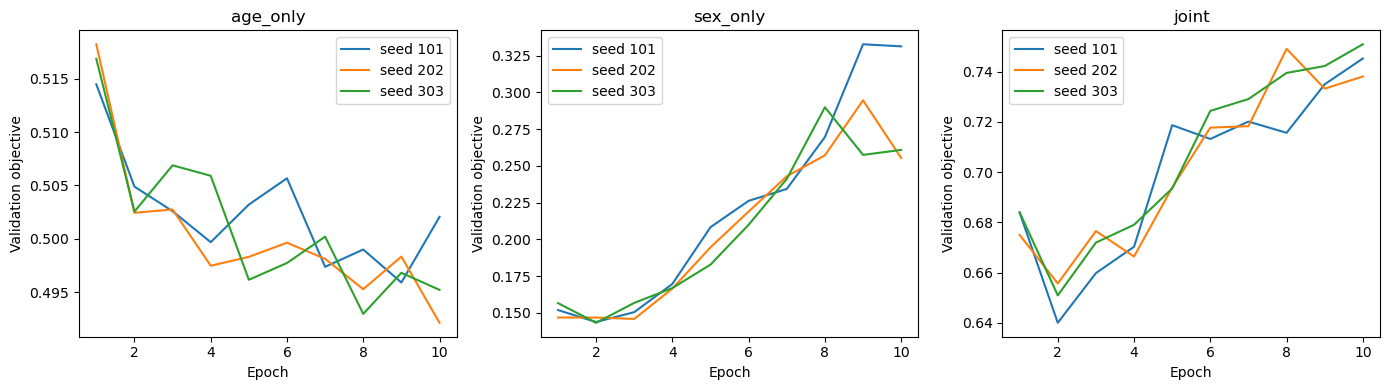

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, task in zip(axes, TASKS):
    for seed in SEEDS:
        key = f'{task}:{seed}'
        if key not in registry: continue
        history = pd.read_csv(Path(registry[key]) / 'history.csv')
        ax.plot(history['epoch'], history['val_loss'], label=f'seed {seed}')
    ax.set(title=task, xlabel='Epoch', ylabel='Validation objective')
    if ax.lines: ax.legend()
plt.tight_layout()
plt.show()


Okay, the baseline experiments finally finished! We ran the age-only, sex-only, and joint models across three matched seeds using the same dataset, splits, and training recipe. On the test set, the age-only model averaged 6.61 years MAE, and the sex-only model averaged 95.83% accuracy, or 4.17% classification error. The joint model averaged 6.79 years MAE and 95.57% sex accuracy, or 4.43% classification error. Its sex cross-entropy was also slightly higher: 0.1373 versus 0.1328 for sex-only.

So far, combining the tasks only slightly hurt both predictions. Compared with the separate models, the joint model’s age error increased by about 0.175 years, and its sex accuracy dropped by about 0.263 percentage points. That happened in all three matched seeds. This suggests some negative transfer under our current setup, but it doesn’t mean joint learning is always worse. These are our no-augmentation baselines; the augmentation experiments will tell us whether rotation, random erasing, or both change that pattern.

### QUICK NOTE:

Quick notebook note: I’m setting RUN_EXPERIMENTS = False and EVALUATE_TEST = False now that the baselines are finished so we don’t accidentally retrain or repeat test evaluation. Before running augmentation experiments, we’ll need to update the code for those conditions and enable execution intentionally. RUN_EXPERIMENTS and EVALUATE_TEST are now independent flags, both set to False for handoff.

One thing to watch: running the settings cell creates a new session folder even when training is disabled. To review our completed baselines, open the saved CSVs in the original results folder. Clicking “Run All” with execution disabled won’t automatically reload our previous results.

# NEXT STEPS:

Okay, our no-augmentation baselines are finished, so the next step is to test the transformations from our proposal: rotation, random erasing, and both together. Each condition needs an age-only, sex-only, and joint model, using seeds 101, 202, and 303. That gives us nine additional configurations and 27 training runs.

Please use the same finalized images, person-disjoint splits, pretrained weights, frozen layers, optimizer, batch size, 10-epoch budget, and loss weights as the baselines. Every run needs a fresh model and optimizer. We’re changing the training augmentation so we can measure its effect without changing the rest of the recipe.

Our saved protocol specifies rotation within ±10 degrees and random erasing with 25% probability, covering 2–10% of the image area, with an aspect-ratio range of 0.3–3.3. For the combined condition, apply rotation *after* resizing/cropping, then convert to a tensor, normalize, and apply erasing. Validation and test images keep the original deterministic preprocessing.

Keep the same checkpoint rules: lowest validation age loss for age-only, cross-entropy for sex-only, and weighted combined loss for joint. Save each condition in a clearly named folder, along with its settings, learning curves, checkpoints, and results. The current notebook only implements no augmentation, so we need to add the transforms and update the configuration labels and logging before launching these runs.

After checking the implementation on development data, lock it and evaluate the selected checkpoints on the same test set. Compare each augmented model against its matching baseline within the same seed, then summarize the differences. Since we’ve already seen baseline test results, we need to stick to the declared augmentation settings rather than adjust them based on test performance. We should also check whether combining the transformations helps more than either one alone and whether augmentation changes the joint-versus-separate gap.
